In [1]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt

In [4]:
df=pd.read_csv('../Data/Raw/Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv')
df.head()

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


In [29]:
print(df.shape)
print(df.columns.tolist())
display(df.dtypes.to_frame(name="Data Type"))

(64000, 12)
['recency', 'history_segment', 'history', 'mens', 'womens', 'zip_code', 'newbie', 'channel', 'segment', 'visit', 'conversion', 'spend']


,Data Type
recency,int64
history_segment,str
history,float64
mens,int64
womens,int64
zip_code,str
newbie,int64
channel,str
segment,str
visit,int64


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int64  
 1   history_segment  64000 non-null  str    
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int64  
 4   womens           64000 non-null  int64  
 5   zip_code         64000 non-null  str    
 6   newbie           64000 non-null  int64  
 7   channel          64000 non-null  str    
 8   segment          64000 non-null  str    
 9   visit            64000 non-null  int64  
 10  conversion       64000 non-null  int64  
 11  spend            64000 non-null  float64
dtypes: float64(2), int64(6), str(4)
memory usage: 5.9 MB


In [6]:
df.describe()

,recency,history,mens,womens,newbie,visit,conversion,spend
count,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000
mean,5.763734,242.085656,0.551031,0.549719,0.502250,0.146781,0.009031,1.050908
std,3.507592,256.158608,0.497393,0.497526,0.499999,0.353890,0.094604,15.036448
min,1.000000,29.990000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,64.660000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,6.000000,158.110000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
75%,9.000000,325.657500,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
max,12.000000,3345.930000,1.000000,1.000000,1.000000,1.000000,1.000000,499.000000


In [35]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
recency,64000.0,NaN,NaN,NaN,5.763734,3.507592,1.0,2.0,6.0,9.0,12.0
history_segment,64000,7,1) $0 - $100,22970,NaN,NaN,NaN,NaN,NaN,NaN,NaN
history,64000.0,NaN,NaN,NaN,242.085656,256.158608,29.99,64.66,158.11,325.6575,3345.93
mens,64000.0,NaN,NaN,NaN,0.551031,0.497393,0.0,0.0,1.0,1.0,1.0
womens,64000.0,NaN,NaN,NaN,0.549719,0.497526,0.0,0.0,1.0,1.0,1.0
zip_code,64000,3,Surburban,28776,NaN,NaN,NaN,NaN,NaN,NaN,NaN
newbie,64000.0,NaN,NaN,NaN,0.50225,0.499999,0.0,0.0,1.0,1.0,1.0
channel,64000,3,Web,28217,NaN,NaN,NaN,NaN,NaN,NaN,NaN
segment,64000,3,Womens E-Mail,21387,NaN,NaN,NaN,NaN,NaN,NaN,NaN
visit,64000.0,NaN,NaN,NaN,0.146781,0.35389,0.0,0.0,0.0,0.0,1.0


In [30]:
df.isnull().sum()

recency            0
history_segment    0
history            0
mens               0
womens             0
zip_code           0
newbie             0
channel            0
segment            0
visit              0
conversion         0
spend              0
dtype: int64

No null values

In [33]:
df.duplicated().sum()

np.int64(6562)

There Are 6562 duplicate rows in our dataset we need to drop these.

In [36]:
df.drop_duplicates(inplace=True)

Dropped duplicated columns

In [37]:
df.shape

(57438, 12)

In [17]:
cat_cols=['history_segment', 'zip_code', 'channel', 'segment','mens', 'womens', 'newbie', 'visit', 'conversion']
num_cols=['recency','history','spend']

In [48]:
for col in cat_cols:
    print(f"\n--- {col} ---")
    display(df[col].value_counts(dropna=False).to_frame("Count"))


--- history_segment ---


,Count
history_segment,
1) $0 - $100,16422
2) $100 - $200,14245
3) $200 - $350,12286
4) $350 - $500,6409
5) $500 - $750,4909
"6) $750 - $1,000",1859
"7) $1,000 +",1308



--- zip_code ---


,Count
zip_code,
Surburban,25650
Urban,22995
Rural,8793



--- channel ---


...

,Count
newbie,
1,28843
0,28595



--- visit ---


,Count
visit,
0,48436
1,9002



--- conversion ---


,Count
conversion,
0,56860
1,578


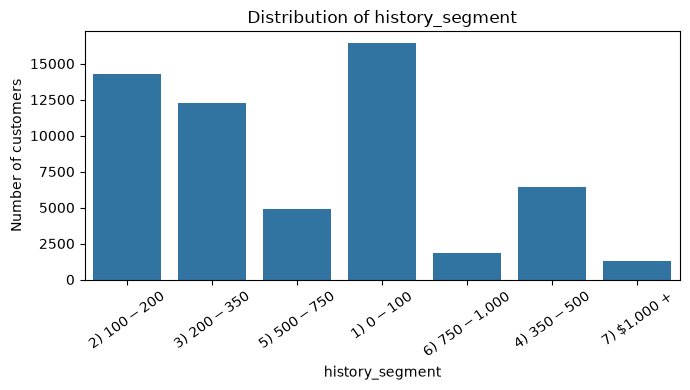

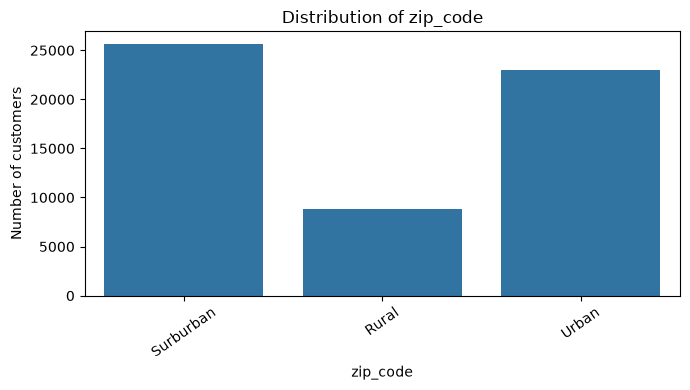

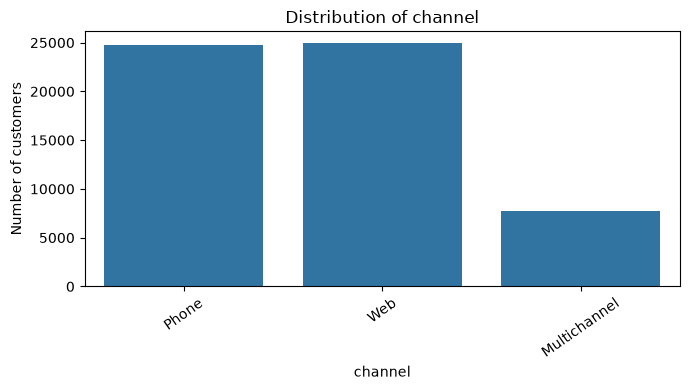

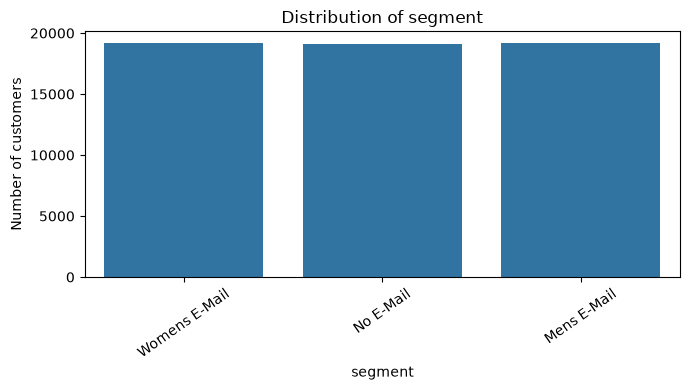

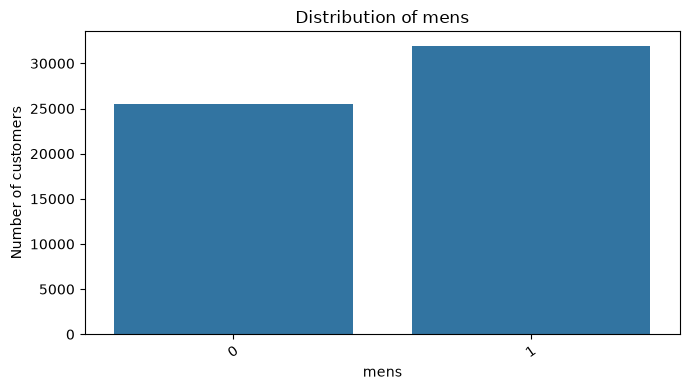

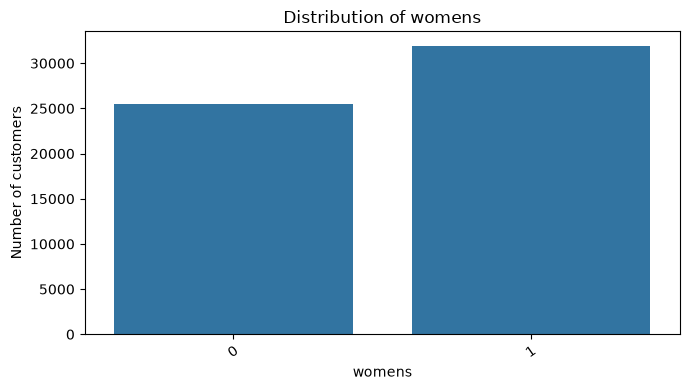

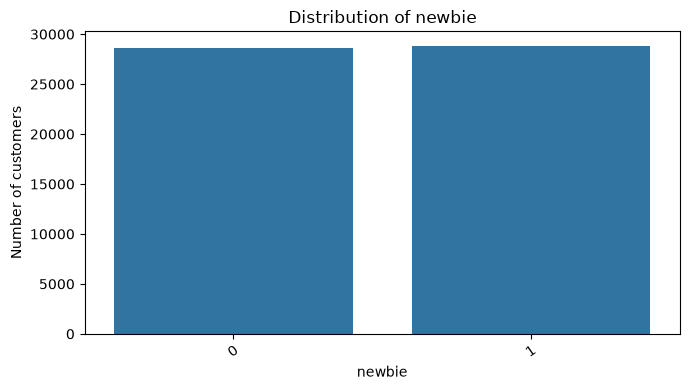

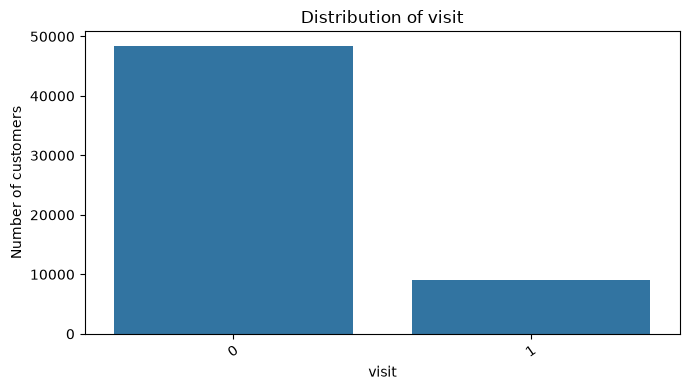

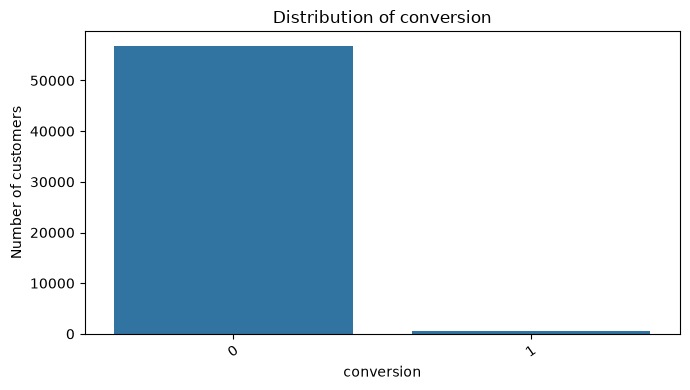

In [50]:
for col in cat_cols:
    plt.figure(figsize=(7, 4))
    sns.countplot(data=df, x=col)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of customers")
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()

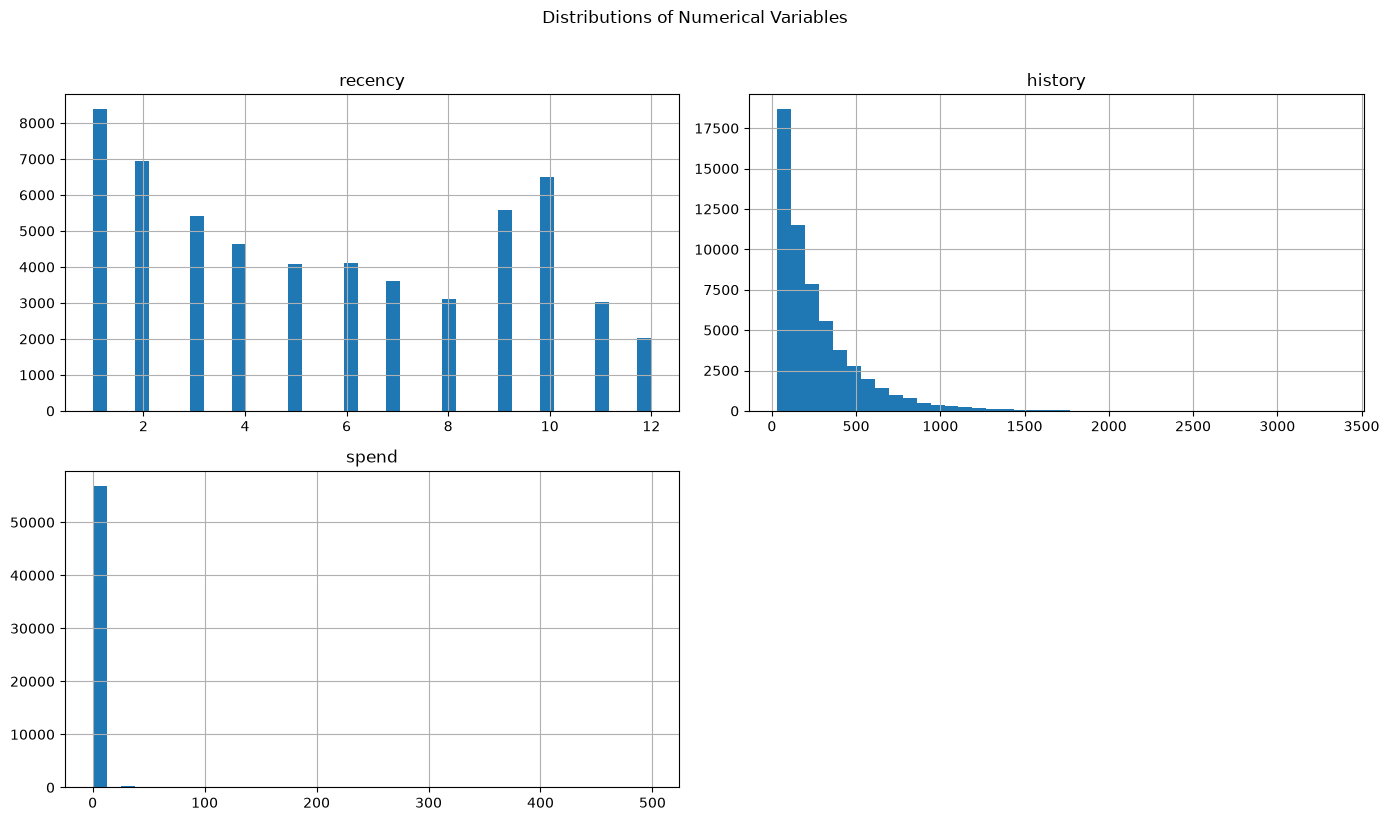

In [53]:

df[num_cols].hist(
        bins=40,
        figsize=(14, 8)
    )

plt.suptitle("Distributions of Numerical Variables", y=1.02)
plt.tight_layout()
plt.show()

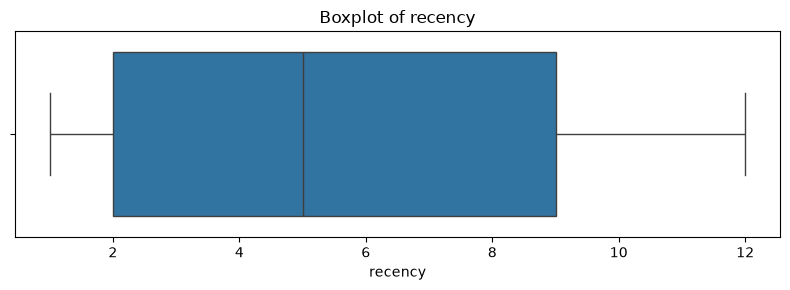

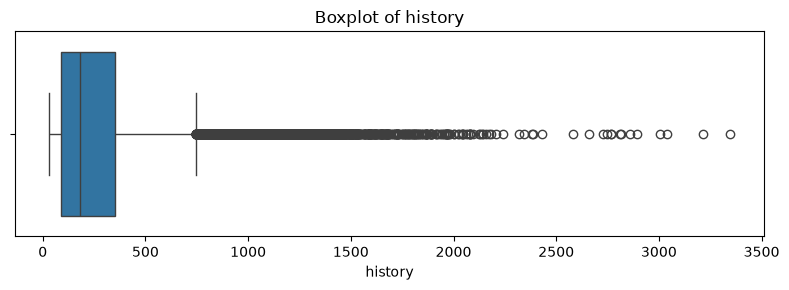

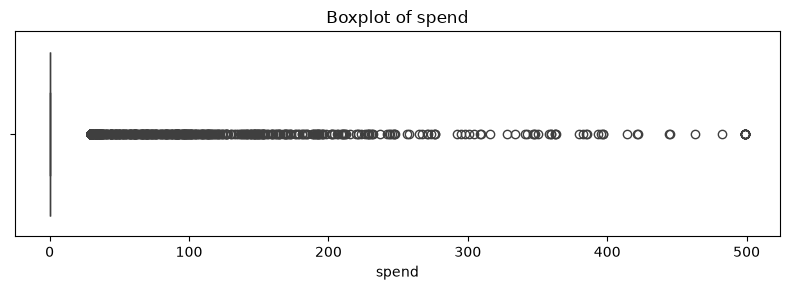

In [54]:
for col in num_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

In [55]:
display(
    df[num_cols].agg(["mean", "median", "std", "min", "max"]).T
)

print("\nSkewness:")
display(df[num_cols].skew().to_frame("Skewness"))

,mean,median,std,min,max
recency,5.662419,5.000,3.502549,1.00,12.00
history,266.259925,183.705,259.612073,29.99,3345.93
spend,1.170969,0.000,15.867729,0.00,499.00



Skewness:


,Skewness
recency,0.182062
history,2.376232
spend,19.500156


# Treatment Analysis

,Customer Count
segment,
Mens E-Mail,19183
Womens E-Mail,19174
No E-Mail,19081


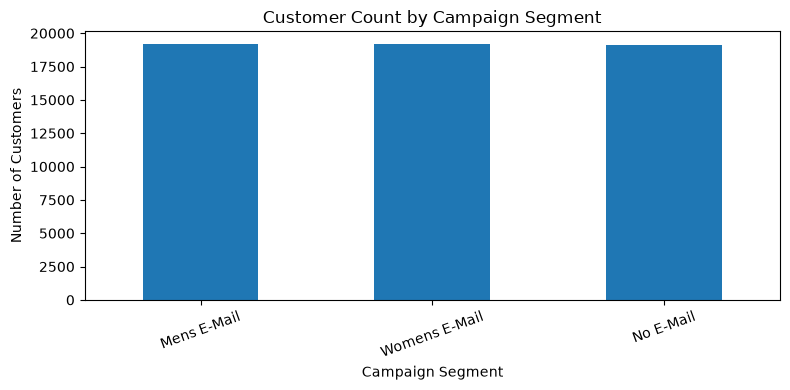

In [56]:
campaign_counts = df["segment"].value_counts()

display(campaign_counts.to_frame("Customer Count"))

campaign_counts.plot(kind="bar", figsize=(8, 4))
plt.title("Customer Count by Campaign Segment")
plt.xlabel("Campaign Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [57]:
conversion_by_segment = (
    df.groupby("segment")["conversion"]
      .agg(["count", "sum", "mean"])
)

conversion_by_segment = conversion_by_segment.rename(
    columns={
        "count": "Customers",
        "sum": "Purchases",
        "mean": "Conversion Rate"
    }
)

conversion_by_segment["Conversion Rate (%)"] = (
    conversion_by_segment["Conversion Rate"] * 100
)

display(conversion_by_segment)

,Customers,Purchases,Conversion Rate,Conversion Rate (%)
segment,,,,
Mens E-Mail,19183,267,0.013919,1.391857
No E-Mail,19081,122,0.006394,0.639379
Womens E-Mail,19174,189,0.009857,0.985710
